In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

df = pd.read_csv('market_features_weekly_std.csv')

df['Date'] = pd.to_datetime(df['Date'])

features = ['SP500_Return', 'VIX', 'Yield_Spread']

X = df[features].values

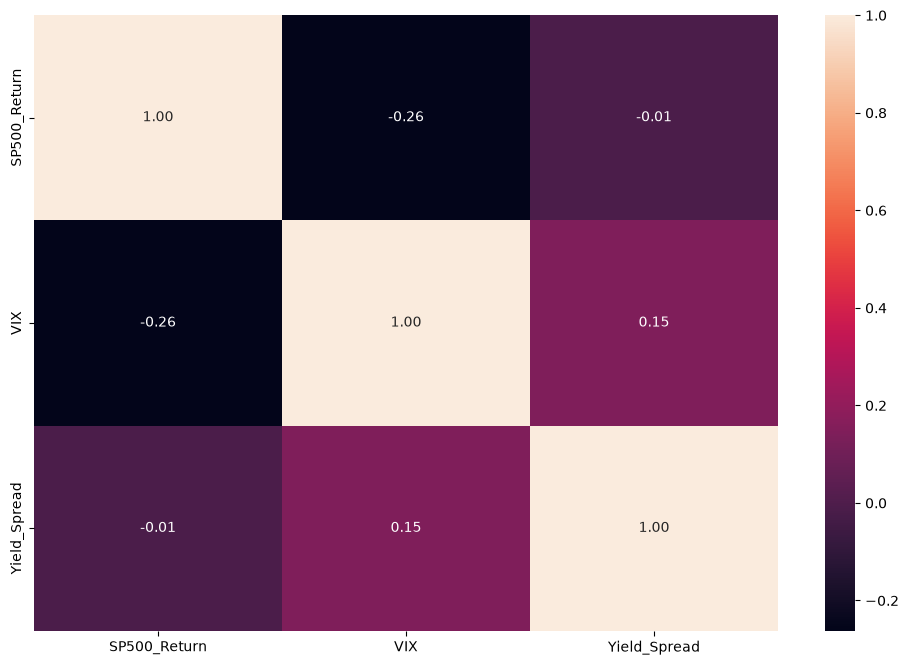

In [9]:
import seaborn as sns

cov_matrix = df[['SP500_Return', 'VIX', 'Yield_Spread']].cov()
plt.figure(figsize=(12, 8))
ax = sns.heatmap(cov_matrix, annot=True, fmt='.2f')
plt.show()
fig = ax.get_figure()
fig.savefig("out.svg", format="svg")

In [4]:
gmm = GaussianMixture(n_components=2, random_state=42)
gmm.fit(X)

,"n_components n_components: int, default=1The number of mixture components.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


In [5]:
df['regime'] = gmm.predict(X)
probs = gmm.predict_proba(X)
regime_stress = df.groupby('regime')['VIX'].mean().idxmax()
df['prob_stress'] = probs[:, regime_stress]

In [6]:
print(df.groupby('regime')[features].mean())

        SP500_Return       VIX  Yield_Spread
regime                                      
0           0.063097 -0.341798     -0.018427
1          -0.274861  1.488929      0.080271


In [7]:
plt.figure(figsize=(14, 5))
plt.scatter(df['Date'], df['SP500_Return'], c=df['prob_stress'], cmap='RdYlGn_r', s=10)
plt.colorbar(label='Probabilità regime stressato')
plt.ylabel('Rendimento S&P 500 (standardizzato)')
plt.title('Regimi di mercato transizioni probabilistiche nel tempo')
plt.show()plt.figure(figsize=(14, 5))
plt.scatter(df['Date'], df['SP500_Return'], c=df['prob_stress'], cmap='RdYlGn_r', s=10)
plt.colorbar(label='Probabilità regime stressato')
plt.ylabel('Rendimento S&P 500 (standardizzato)')
plt.title('Regimi di mercato transizioni probabilistiche nel tempo')
plt.show()

SyntaxError: invalid syntax (3091795456.py, line 6)